In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

In [6]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
os.makedirs("eda_plots", exist_ok=True)

In [7]:
CSV_PATH = None
try:
    from google.colab import files
    uploaded = files.upload()          # choose your .csv file
    csv_files = [n for n in uploaded if n.lower().endswith(".csv")]
    assert csv_files, "No .csv file uploaded. Please upload a .csv file."
    CSV_PATH = csv_files[0]            # uses whatever name the file has
except ImportError:
    # Not running in Colab: fall back to a local file
    CSV_PATH = "amazon.csv"

assert os.path.exists(CSV_PATH), f"{CSV_PATH} not found. Upload it first."
print("Using file:", CSV_PATH)


def save(name):
    plt.tight_layout()
    plt.savefig(f"eda_plots/{name}.png", dpi=120)
    plt.show()

Saving amazon.csv to amazon.csv
Using file: amazon.csv


In [8]:
df = pd.read_csv(CSV_PATH)

In [9]:
print("Shape:", df.shape)

Shape: (1465, 16)


In [10]:
display(df.head())

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


In [11]:
display(df.dtypes.to_frame("dtype"))

,dtype
product_id,object
product_name,object
category,object
discounted_price,object
actual_price,object
discount_percentage,object
rating,object
rating_count,object
about_product,object
user_id,object


In [12]:
display(df.isna().sum().to_frame("missing"))

,missing
product_id,0
product_name,0
category,0
discounted_price,0
actual_price,0
discount_percentage,0
rating,0
rating_count,2
about_product,0
user_id,0


In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [14]:
print("Duplicate product_ids:", df["product_id"].duplicated().sum())

Duplicate product_ids: 114


In [15]:
print("Unique products:", df["product_id"].nunique())

Unique products: 1351


In [16]:
for c in ["discounted_price", "actual_price"]:
    df[c] = df[c].str.replace("[₹,]", "", regex=True).astype(float)
df["discount_percentage"] = df["discount_percentage"].str.replace("%", "").astype(float)

In [17]:
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["rating_count"] = pd.to_numeric(df["rating_count"].str.replace(",", ""), errors="coerce")

In [18]:
cats = df["category"].str.split("|", expand=True)
df["main_category"] = cats[0]
df["sub_category"] = cats[1]
df["leaf_category"] = cats.ffill(axis=1).iloc[:, -1]

In [19]:
print("Rows with missing rating/rating_count:",
      df[["rating", "rating_count"]].isna().any(axis=1).sum())
df["rating_count"] = df["rating_count"].fillna(df["rating_count"].median())
df["rating"] = df["rating"].fillna(df["rating"].median())

Rows with missing rating/rating_count: 3


In [20]:
df = df.drop_duplicates(subset="product_id").reset_index(drop=True)
df["savings"] = df["actual_price"] - df["discounted_price"]
print("After cleaning:", df.shape)

After cleaning: (1351, 20)


,discounted_price,actual_price,discount_percentage,rating,rating_count,savings
count,1351.00,1351.00,1351.00,1351.00,1351.00,1351.00
mean,3304.80,5691.18,46.69,4.09,17626.04,2386.37
std,7173.98,11218.67,21.63,0.30,42117.14,4736.44
min,39.00,39.00,0.00,2.00,2.00,0.00
25%,349.00,899.00,31.00,3.90,1107.00,380.00
50%,899.00,1795.00,49.00,4.10,4740.00,801.00
75%,2174.00,4575.00,62.00,4.30,15995.00,2000.00
max,77990.00,139900.00,94.00,5.00,426973.00,61910.00


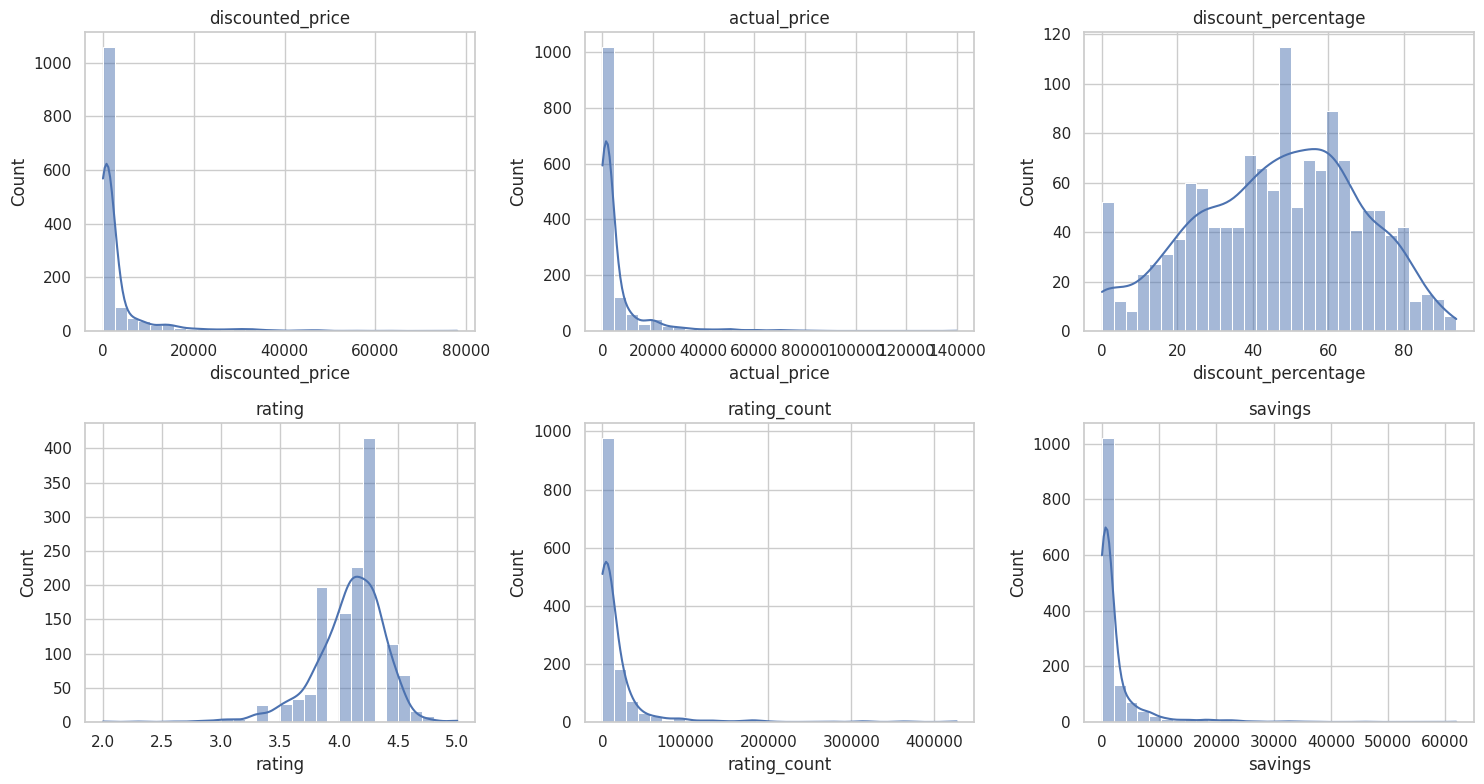

Skewness:


,skew
discounted_price,4.30
actual_price,4.43
rating_count,5.69


In [21]:
num_cols = ["discounted_price", "actual_price", "discount_percentage",
            "rating", "rating_count", "savings"]
display(df[num_cols].describe().round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
save("01_distributions")

print("Skewness:")
display(df[["discounted_price", "actual_price", "rating_count"]].skew().round(2).to_frame("skew"))

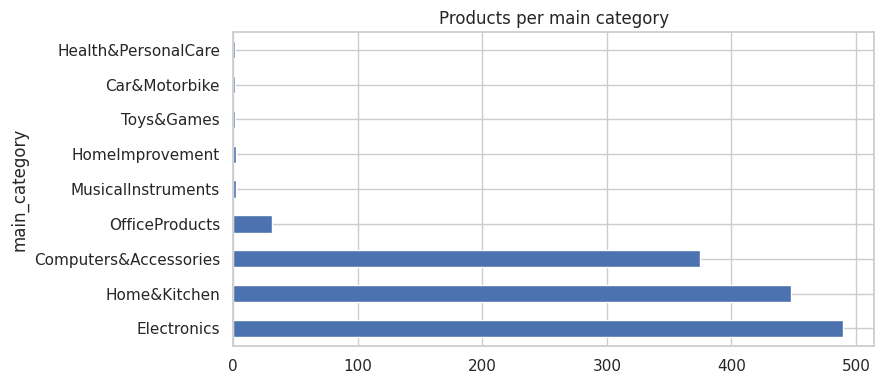

In [22]:
plt.figure(figsize=(9, 4))
df["main_category"].value_counts().plot(kind="barh")
plt.title("Products per main category")
save("02_category_counts")

In [23]:
cat_summary = (df.groupby("main_category")
                 .agg(products=("product_id", "count"),
                      avg_discount=("discount_percentage", "mean"),
                      avg_rating=("rating", "mean"),
                      total_reviews=("rating_count", "sum"),
                      avg_price=("discounted_price", "mean"))
                 .round(2).sort_values("products", ascending=False))
display(cat_summary)

,products,avg_discount,avg_rating,total_reviews,avg_price
main_category,,,,,
Electronics,490,49.91,4.08,14208406.0,6225.87
Home&Kitchen,448,40.12,4.04,2991069.0,2330.62
Computers&Accessories,375,53.22,4.15,6345535.0,947.49
OfficeProducts,31,12.35,4.31,149675.0,301.58
MusicalInstruments,2,46.00,3.90,88882.0,638.00
HomeImprovement,2,57.50,4.25,8566.0,337.00
Car&Motorbike,1,42.00,3.80,1118.0,2339.00
Health&PersonalCare,1,53.00,4.00,3663.0,899.00
Toys&Games,1,0.00,4.30,15867.0,150.00


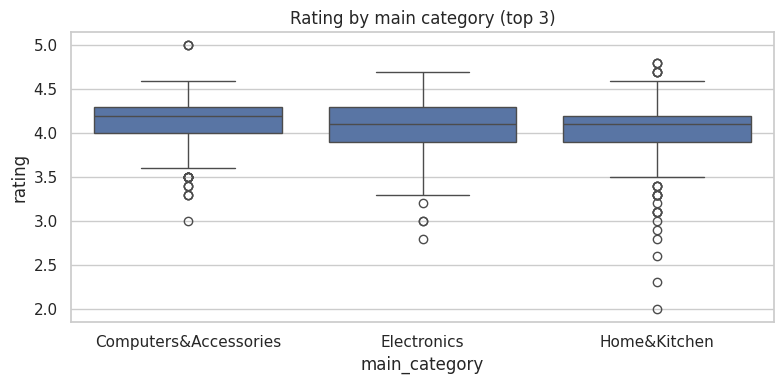

In [24]:
top3 = df["main_category"].value_counts().head(3).index
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[df["main_category"].isin(top3)], x="main_category", y="rating")
plt.title("Rating by main category (top 3)")
save("03_rating_by_category")

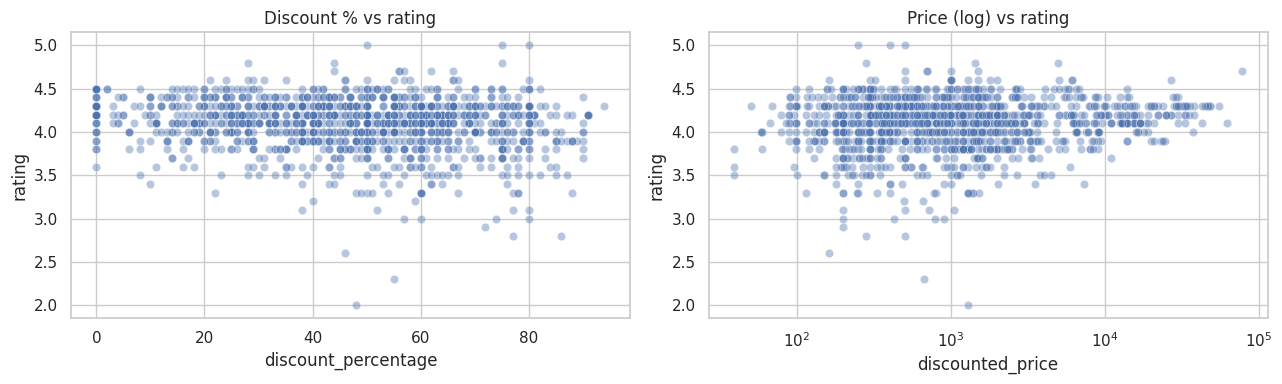

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x="discount_percentage", y="rating", alpha=0.4, ax=axes[0])
sns.scatterplot(data=df, x="discounted_price", y="rating", alpha=0.4, ax=axes[1])
axes[1].set_xscale("log")
axes[0].set_title("Discount % vs rating")
axes[1].set_title("Price (log) vs rating")
save("04_scatter_discount_price_vs_rating")

In [26]:
top_pop = df.nlargest(10, "rating_count")[["product_name", "rating", "rating_count"]]
display(top_pop)
print("Note: colour variants of one product share the same rating_count, so totals are inflated.")

,product_name,rating,rating_count
12,AmazonBasics Flexible Premium HDMI Cable (Blac...,4.4,426973.0
47,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",4.4,426973.0
65,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",4.4,426973.0
352,boAt Bassheads 100 in Ear Wired Earphones with...,4.1,363713.0
395,boAt Bassheads 100 in Ear Wired Earphones with...,4.1,363713.0
557,boAt BassHeads 100 in-Ear Wired Headphones wit...,4.1,363711.0
369,"Redmi 9 Activ (Carbon Black, 4GB RAM, 64GB Sto...",4.1,313836.0
370,"Redmi 9A Sport (Coral Green, 2GB RAM, 32GB Sto...",4.1,313836.0
456,"Redmi 9A Sport (Carbon Black, 2GB RAM, 32GB St...",4.1,313832.0
541,"Redmi 9A Sport (Coral Green, 3GB RAM, 32GB Sto...",4.1,313832.0


Note: colour variants of one product share the same rating_count, so totals are inflated.


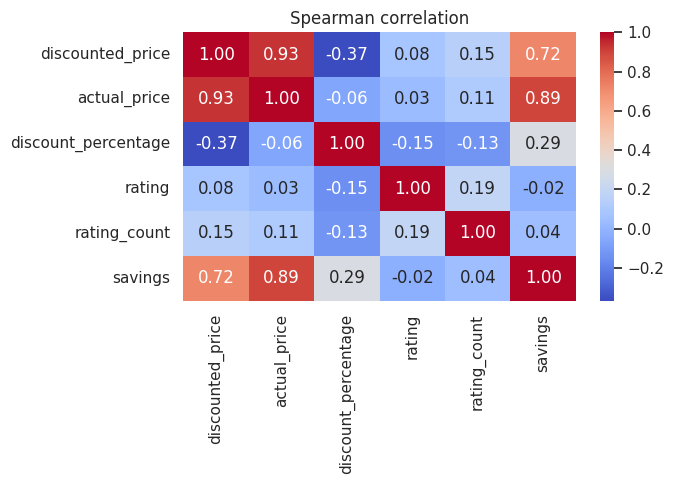

,IQR outliers
discounted_price,209
actual_price,185
rating_count,130
rating,19


In [27]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Spearman correlation")
save("05_correlation")


def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


display(pd.Series({c: iqr_outliers(df[c]) for c in
                   ["discounted_price", "actual_price", "rating_count", "rating"]},
                  name="IQR outliers").to_frame())

In [28]:
df["discount_bucket"] = pd.cut(df["discount_percentage"], [-1, 20, 40, 60, 80, 100],
                               labels=["0-20", "20-40", "40-60", "60-80", "80-100"])
df["price_band"] = pd.cut(df["discounted_price"], [0, 500, 1000, 5000, 20000, np.inf],
                          labels=["<500", "500-1k", "1k-5k", "5k-20k", "20k+"])
df["popularity"] = pd.qcut(df["rating_count"], 4, labels=["Low", "Medium", "High", "Very High"])
df["rating_band"] = pd.cut(df["rating"], [0, 3.5, 4.0, 4.5, 5],
                           labels=["<=3.5", "3.5-4.0", "4.0-4.5", "4.5+"])

display(df.groupby("discount_bucket", observed=True)["rating"].agg(["count", "mean"]).round(2))
display(df.groupby("price_band", observed=True)["rating"].agg(["count", "mean"]).round(2))

,count,mean
discount_bucket,,
0-20,176,4.17
20-40,329,4.13
40-60,469,4.07
60-80,326,4.07
80-100,51,3.97


,count,mean
price_band,,
<500,501,4.07
500-1k,237,4.11
1k-5k,410,4.07
5k-20k,152,4.15
20k+,51,4.24


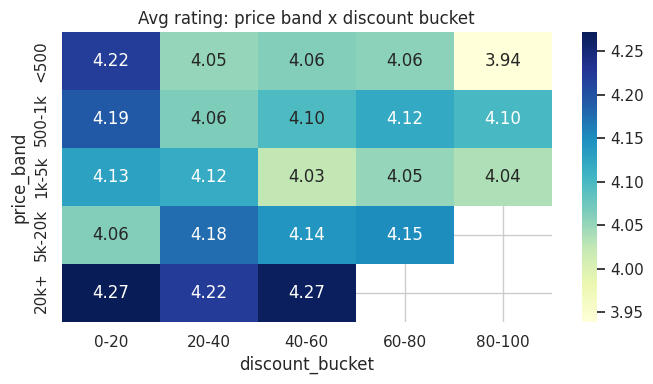

In [29]:
pivot = df.pivot_table(index="price_band", columns="discount_bucket",
                       values="rating", aggfunc="mean", observed=True)
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Avg rating: price band x discount bucket")
save("06_price_discount_rating_heatmap")

In [30]:
rho, p = stats.spearmanr(df["discount_percentage"], df["rating"])
print(f"Q1. Discount vs rating: rho={rho:.3f}, p={p:.4f}")

Q1. Discount vs rating: rho=-0.149, p=0.0000


In [31]:
groups = [g["rating"].values for _, g in df[df["main_category"].isin(top3)].groupby("main_category")]
h, p = stats.kruskal(*groups)
print(f"Q2. Rating differs across top-3 categories: H={h:.2f}, p={p:.4f}")

Q2. Rating differs across top-3 categories: H=34.19, p=0.0000


In [32]:
heavy = df.loc[df["discount_percentage"] >= 60, "rating"]
light = df.loc[df["discount_percentage"] < 40, "rating"]
u, p = stats.mannwhitneyu(heavy, light)
print(f"Q3. Heavy vs light discount: U={u:.0f}, p={p:.4f} (means {heavy.mean():.2f} vs {light.mean():.2f})")

Q3. Heavy vs light discount: U=82562, p=0.0000 (means 4.04 vs 4.14)


In [33]:
sub = (df.groupby("sub_category")
         .agg(n=("product_id", "count"), avg_discount=("discount_percentage", "mean"),
              avg_rating=("rating", "mean"), reviews=("rating_count", "sum"))
         .query("n >= 10").round(2).sort_values("avg_discount", ascending=False))
display(sub.head(10))

,n,avg_discount,avg_rating,reviews
sub_category,,,,
WearableTechnology,62,69.68,4.01,1227958.0
"Headphones,Earbuds&Accessories",63,59.49,3.92,4548406.0
Accessories,11,55.91,4.36,943255.0
Accessories&Peripherals,307,55.44,4.14,3751461.0
HomeAudio,16,49.69,4.07,293704.0
"HomeTheater,TV&Video",156,49.39,4.07,2371410.0
Cameras&Photography,16,47.56,4.12,322657.0
NetworkingDevices,30,47.20,4.16,1346612.0
ExternalDevices&DataStorage,18,46.89,4.32,1037012.0


In [34]:
C = df["rating"].mean()
m = df["rating_count"].quantile(0.75)
df["weighted_rating"] = ((df["rating_count"] / (df["rating_count"] + m)) * df["rating"]
                         + (m / (df["rating_count"] + m)) * C)
display(df.nlargest(10, "weighted_rating")[["product_name", "rating", "rating_count",
                                            "weighted_rating"]].round(2))

,product_name,rating,rating_count,weighted_rating
1031,Swiffer Instant Electric Water Heater Faucet T...,4.8,53803.0,4.64
779,SanDisk Extreme SD UHS I 64GB Card for 4K Vide...,4.5,205052.0,4.47
40,AmazonBasics USB 2.0 Cable - A-Male to B-Male ...,4.5,107687.0,4.45
734,Crucial BX500 240GB 3D NAND SATA 6.35 cm (2.5-...,4.5,92925.0,4.44
743,Redgear MP35 Speed-Type Gaming Mousepad (Black...,4.6,33434.0,4.44
212,AmazonBasics USB 2.0 Extension Cable for Perso...,4.5,74977.0,4.43
30,AmazonBasics USB 2.0 - A-Male to A-Female Exte...,4.5,74976.0,4.43
436,Spigen EZ Fit Tempered Glass Screen Protector ...,4.6,26603.0,4.41
665,"Logitech M235 Wireless Mouse, 1000 DPI Optical...",4.5,54405.0,4.41
583,Seagate Expansion 1TB External HDD - USB 3.0 f...,4.5,50810.0,4.40


In [35]:
df["price_vs_cat_median"] = df["actual_price"] / df.groupby("main_category")["actual_price"].transform("median")
flag = (df["price_vs_cat_median"] > 5) & (df["discount_percentage"] >= 70)
print("Products with MRP > 5x category median and 70%+ discount:", int(flag.sum()))
display(df.loc[flag, ["product_name", "actual_price", "discounted_price", "discount_percentage"]].head(10))

Products with MRP > 5x category median and 70%+ discount: 16


,product_name,actual_price,discounted_price,discount_percentage
334,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0
364,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0
368,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0
371,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0
374,"Fire-Boltt Visionary 1.78"" AMOLED Bluetooth Ca...",16999.0,3999.0,76.0
377,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",19999.0,1799.0,91.0
399,Samsung Galaxy Buds Live Bluetooth Truly Wirel...,15990.0,4790.0,70.0
547,"Fire-Boltt Visionary 1.78"" AMOLED Bluetooth Ca...",17999.0,3999.0,78.0
635,"rts [2 Pack] Mini USB C Type C Adapter Plug, T...",4999.0,294.0,94.0
668,Callas Multipurpose Foldable Laptop Table with...,4999.0,849.0,83.0


In [36]:
pos = ["good", "great", "excellent", "best", "value for money", "nice", "perfect"]
neg = ["bad", "poor", "worst", "waste", "not good", "defective", "disappointed"]
t = df["review_title"].fillna("").str.lower()
df["pos_hits"] = sum(t.str.count(w) for w in pos)
df["neg_hits"] = sum(t.str.count(w) for w in neg)
df["sentiment_score"] = df["pos_hits"] - df["neg_hits"]
print("Spearman: sentiment_score vs rating =",
      round(df["sentiment_score"].corr(df["rating"], method="spearman"), 3))

Spearman: sentiment_score vs rating = 0.19


In [37]:
keep = ["product_id", "product_name", "main_category", "sub_category", "leaf_category",
        "discounted_price", "actual_price", "discount_percentage", "savings",
        "rating", "rating_count", "weighted_rating", "discount_bucket", "price_band",
        "popularity", "rating_band", "sentiment_score"]
df[keep].to_csv("amazon_clean.csv", index=False)
print("Saved amazon_clean.csv:", df[keep].shape)

Saved amazon_clean.csv: (1351, 17)


In [38]:
try:
    import shutil
    shutil.make_archive("eda_plots", "zip", "eda_plots")
    files.download("amazon_clean.csv")
    files.download("eda_plots.zip")
except NameError:
    print("Files saved locally: amazon_clean.csv and eda_plots/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>